# Step 2: Rewriting products with an LLM (does it help, or just cost money?)

**Why this notebook exists**

`01_curation.ipynb` produced a clean, balanced dataset: 25,022 Shopify products, 141 categories
([raghu619/shopify_category_lite](https://huggingface.co/datasets/raghu619/shopify_category_lite)).
The goal is to fine-tune a model that reads a product and names its category.

The text is still messy: long marketing copy, product codes, mixed languages. A common fix (Week 6 Day 2 of the
LLM Engineering course) is to have a cheap LLM rewrite every product into one short, standard format first.

Expected benefits:
1. **Cleaner input:** every product looks the same (title, brand, description, details).
2. **Cheaper fine-tuning:** fine-tuning is billed per token, so shorter examples mean a cheaper run.

Hidden costs, which is why we measure instead of assuming:
1. **Leakage risk:** the course prompt asks for a `Category:` line. Here the category is the *answer*, so that line must go.
   Even without it, the LLM may name the category anyway. We measure how often.
2. **Train/serve consistency:** if the model trains on rewritten text, every future product must be rewritten the same way
   before it can be classified. That's an extra LLM call per product, forever.

**Output of this notebook:** a `summary` column (the rewrite) next to the original `text`, so Day 3 can compare
*raw vs rewritten* on the same model.

| Step | What | Course concept |
|---|---|---|
| 1 | Setup and load our dataset | |
| 2 | Design the prompt, test on a few products | LLM as a data cleaner, prompt as spec |
| 3 | Leakage check on the test outputs | (our addition) |
| 4 | 100-item Batch API sample, measure cost | Batch API, JSONL, custom_id, sample-then-project |
| 5 | Full run, resumable | Chunking, idempotent re-runs, safety asserts |
| 6 | Before/after charts, publish | |

## Step 1: Setup

Install the two libraries this notebook needs (into your user folder, same as `pyarrow` before).
If they're already installed, this does nothing.

In [ ]:
%pip install --user -q openai python-dotenv

We use the `openai` library directly (not `litellm` like the course) because the Batch API we use later is
OpenAI-specific anyway. Fewer libraries, fewer things to break.

The API key is read from the course folder's `.env`, so the key is never copied into this project or printed.
Every product gets an `id`: batch answers come back in any order, and the id matches each answer to its product.

In [ ]:
# Cell 1: libraries, API key, and our curated dataset
import os
import json
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI
from tqdm.auto import tqdm

# Key lives in the course repo's .env. Load it from there; never print it.
load_dotenv("/Users/raghvendaraokoduri/projects/llm_engineering/.env", override=True)
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found in the .env file"
print("OpenAI key loaded:", bool(os.getenv("OPENAI_API_KEY")))
client = OpenAI()

# Our Day 1 output, straight from Hugging Face
REPO = "raghu619/shopify_category_lite"
parts = {}
for s in tqdm(["train", "validation", "test"], desc="Loading splits from Hugging Face", unit="split"):
    parts[s] = pd.read_parquet(f"hf://datasets/{REPO}/data/{s}.parquet")

# One table for ALL splits: every product must be rewritten the same way (train/serve consistency)
df = pd.concat([d.assign(split=s) for s, d in parts.items()], ignore_index=True)
df["id"] = df.index          # stable id, used as custom_id in the Batch API

print(f"\nLoaded {len(df):,} products | {df['label'].nunique()} classes")
print(df["split"].value_counts().to_string())

# Read one real row before doing anything with it
row = df.iloc[0]
print(f"\nExample id={row['id']}  label={row['label']}")
print(row["text"][:600])
print(f"\nText length: median {df['text'].str.len().median():.0f} chars, max {df['text'].str.len().max():,}")


### Step 1 finding: some products have almost no information
Product id 0 is just the word **"Marriage"**, labelled `Media > Podcasts & Live Streams`. Nobody could infer "podcast" from that.

This is the main risk of LLM rewriting: asked to "write a description", an LLM may **invent** one ("A book about modern relationships").
That's a **hallucination**, and it would put false facts into training data. The prompt below forbids inventing, and we test it on this exact product.

## Step 2: Design the prompt and test it on 5 hand-picked products

The system prompt is the **specification** for every rewrite. Compared with the course prompt:

| Course prompt (price prediction) | Our prompt (category prediction) | Why |
|---|---|---|
| Has a `Category:` line | **No category line** | Here the category is the answer. Asking for it = leakage |
| No rule about missing info | **"Never invent facts, write Unknown"** | Products like "Marriage" tempt the LLM to hallucinate |
| English input assumed | **"Translate to English"** | ~9% Spanish, some French |
| | **"Do not mention category or department"** | Reduce the chance the LLM adds category hints |

We test on **edge cases on purpose**, not random products: the near-empty one, a title-only one, a Spanish one, the longest one, and one random.
Testing only typical products would hide exactly the failures we care about.

`temperature=0` makes the output as consistent as possible: a data-cleaning step should give the same answer every time.

In [4]:
# Cell 2: the rewrite prompt (the "spec") and a function that calls the LLM once
MODEL = "gpt-4.1-nano"     # cheapest capable OpenAI model, same as the course
MAX_TOKENS = 200           # the 4-line output is ~50 to 100 tokens; this is a safety cap

SYSTEM_PROMPT = """You rewrite e-commerce product listings into a short, standard format.
Respond in English, in exactly this format and nothing else:
Title: short, precise product title
Brand: brand name, or Unknown
Description: one sentence on what the product is
Details: one sentence on key features (material, size, colour, quantity), or Unknown

Rules:
- Use only information in the listing. Never invent facts. If something is missing, write Unknown.
- Do not mention the product's category or store department.
- Remove part numbers, SKUs, prices, URLs, contact details and marketing slogans.
- If the listing is not in English, translate it into English."""

def rewrite(text: str):
    """Rewrite one product. Returns (summary, input_tokens, output_tokens)."""
    response = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": text}],
        max_tokens=MAX_TOKENS,
        temperature=0,
    )
    usage = response.usage
    return response.choices[0].message.content, usage.prompt_tokens, usage.completion_tokens

print("Prompt ready. System prompt length:", len(SYSTEM_PROMPT), "chars")


Prompt ready. System prompt length: 644 chars


In [5]:
# Cell 3: test the prompt on 5 deliberately difficult products (with a progress bar)
# Standard (non-batch) gpt-4.1-nano prices in USD per 1M tokens. Check https://openai.com/api/pricing
INPUT_PRICE, OUTPUT_PRICE = 0.10, 0.40

# How common are near-empty products?
no_desc = ~df["text"].str.contains("\n")
print(f"Title-only products (no description): {no_desc.sum():,} ({no_desc.mean():.1%})")
print(f"Texts under 30 characters:            {(df['text'].str.len() < 30).sum():,}")

# Pick the edge cases
lower = df["text"].str.lower()
spanish = lower.str.count(r"\b(?:para|con|del|los|las|una|por)\b") > lower.str.count(r"\b(?:the|and|for|with)\b")
picks = {
    "near-empty (id 0)": 0,
    "title only": int(df.loc[no_desc & (df.index != 0)].sample(1, random_state=1)["id"].iloc[0]),
    "Spanish": int(df.loc[spanish].sample(1, random_state=1)["id"].iloc[0]),
    "longest": int(df["text"].str.len().idxmax()),
    "random": int(df.sample(1, random_state=7)["id"].iloc[0]),
}

results = []
for kind, pid in tqdm(picks.items(), desc="Rewriting test products", unit="product"):
    summary, tin, tout = rewrite(df.loc[pid, "text"])
    results.append({"kind": kind, "id": pid, "summary": summary, "in": tin, "out": tout})

for r in results:
    row = df.loc[r["id"]]
    print("=" * 90)
    print(f"[{r['kind']}]  id={r['id']}  TRUE LABEL: {row['label']}")
    print(f"ORIGINAL ({len(row['text'])} chars): {row['text'][:300]!r}")
    print(f"REWRITE  ({r['in']} in / {r['out']} out tokens):")
    print(r["summary"])

tin = sum(r["in"] for r in results)
tout = sum(r["out"] for r in results)
cost = (tin * INPUT_PRICE + tout * OUTPUT_PRICE) / 1_000_000
print("=" * 90)
print(f"5 products: {tin:,} input + {tout:,} output tokens = ${cost:.5f}")
print(f"Rough projection for {len(df):,} products at standard price: ${cost / len(results) * len(df):.2f} "
      f"(Batch API will be ~50% of that)")


Title-only products (no description): 1,705 (6.8%)
Texts under 30 characters:            625


Rewriting test products:   0%|          | 0/5 [00:00<?, ?product/s]

[near-empty (id 0)]  id=0  TRUE LABEL: Media > Podcasts & Live Streams
ORIGINAL (8 chars): 'Marriage'
REWRITE  (148 in / 26 out tokens):
Title: Marriage  
Brand: Unknown  
Description: A concept or event related to the union of two people.  
Details: Unknown
[title only]  id=10214  TRUE LABEL: Food, Beverages & Tobacco > Tobacco Products
ORIGINAL (91 chars): 'OCB Unbleached Slim Virgin Paper, langes Papier, Braun, 12,5 cm 11,5 cm breit x 5,5 cm hoch'
REWRITE  (180 in / 62 out tokens):
Title: OCB Unbleached Slim Virgin Paper  
Brand: Unknown  
Description: Unbleached slim paper in a pack of 12.5 cm by 11.5 cm, 5.5 cm high  
Details: Made of unbleached material, brown color, quantity of 12 sheets
[Spanish]  id=17853  TRUE LABEL: Baby & Toddler > Diapering
ORIGINAL (212 chars): "Cooper Eosine 2% Soluzione Cutanea Asciugante 50ml\nSoluzione per l'applicazione locale al fine di asciugare la pelle, specialmente nel neonato (irritazione e arrossamento dei glutei, cura del cordone ombelicale).

### Step 2 findings (prompt v1)
- **"Marriage" was interpreted, not reported:** "A concept or event related to the union of two people." It should have said Unknown; the true label is a podcast.
- **A real hallucination despite "never invent":** OCB paper `12,5 cm` (German decimal comma) became "quantity of **12 sheets**".
- **Over-caution:** `Brand: Unknown` for OCB and Cooper, both the first word of the title.
- **Languages:** the "Spanish" pick was **Italian**, and OCB was **German**. The data has Spanish, French, German and Italian, not "9% Spanish".
- Cost: 5 products for $0.00028, projected ~$1.40 standard / ~$0.70 Batch API for all 25,022.

Lessons: a prompt rule is a request, not a guarantee. Fixing hallucination with "don't invent" made the model too cautious. Locale formats (`12,5` vs `12.5`) break naive readers, human or LLM.

## Step 2b: Prompt v2, tested on the SAME 5 products

Three targeted changes, one per failure:
1. **Brand:** take it from the listing when present (often the first word of the title).
2. **Too little information:** `Description: Unknown`, never guess what a word means.
3. **Numbers:** copy numbers and units exactly; a comma can be a decimal separator; never turn a measurement into a quantity.

Same 5 products as v1 = a **regression test**: fixed inputs, so any difference comes from the prompt, not from easier examples.

We also add an **automatic hallucination check for numbers**: any number in the rewrite that doesn't appear in the original listing is flagged.
Reading 5 outputs by eye works; reading 25,022 doesn't. Checks like this scale.

In [6]:
# Cell 4: prompt v2 + side-by-side comparison with v1 on the same 5 products
import re

SYSTEM_PROMPT_V2 = """You rewrite e-commerce product listings into a short, standard format.
Respond in English, in exactly this format and nothing else:
Title: short, precise product title
Brand: the brand name if it appears in the listing (often the first word of the title), otherwise Unknown
Description: one sentence on what the product is
Details: one sentence on key features (material, size, colour, quantity), or Unknown

Rules:
- Use only information in the listing. Never invent facts.
- If the listing is too short to tell what the product is, write "Description: Unknown". Do not guess what a word means.
- Copy numbers and units exactly as written. A comma may be a decimal separator (12,5 cm means 12.5 cm).
  Never turn a measurement into a quantity.
- Do not mention the product's category or store department.
- Remove part numbers, SKUs, prices, URLs, contact details and marketing slogans.
- If the listing is not in English, translate it into English."""

def rewrite_with(prompt: str, text: str):
    """Same as rewrite(), but with an explicit prompt so versions can be compared."""
    response = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "system", "content": prompt}, {"role": "user", "content": text}],
        max_tokens=MAX_TOKENS,
        temperature=0,
    )
    u = response.usage
    return response.choices[0].message.content, u.prompt_tokens, u.completion_tokens

def numbers_in(text: str) -> set:
    """All numbers in a text, with decimal commas normalised (12,5 -> 12.5)."""
    text = re.sub(r"(\d),(\d)", r"\1.\2", text)
    return set(re.findall(r"\d+(?:\.\d+)?", text))

def invented_numbers(original: str, summary: str) -> set:
    """Numbers that appear in the rewrite but nowhere in the original listing."""
    return numbers_in(summary) - numbers_in(original)

def brand_line(summary: str) -> str:
    m = re.search(r"Brand:\s*(.*)", summary)
    return m.group(1).strip() if m else "(missing)"

v2_results = []
for r in tqdm(results, desc="Rewriting with prompt v2", unit="product"):
    summary, tin, tout = rewrite_with(SYSTEM_PROMPT_V2, df.loc[r["id"], "text"])
    v2_results.append({**r, "summary_v2": summary, "in_v2": tin, "out_v2": tout})

for r in v2_results:
    original = df.loc[r["id"], "text"]
    print("=" * 90)
    print(f"[{r['kind']}]  id={r['id']}  TRUE LABEL: {df.loc[r['id'], 'label']}")
    print(f"ORIGINAL: {original[:200]!r}")
    print(f"\n--- v1 ---  brand: {brand_line(r['summary'])} | invented numbers: {invented_numbers(original, r['summary']) or 'none'}")
    print(r["summary"])
    print(f"\n--- v2 ---  brand: {brand_line(r['summary_v2'])} | invented numbers: {invented_numbers(original, r['summary_v2']) or 'none'}")
    print(r["summary_v2"])

# Scorecard
def score(key):
    unknown_brands = sum(brand_line(r[key]) == "Unknown" for r in v2_results)
    invented = sum(bool(invented_numbers(df.loc[r["id"], "text"], r[key])) for r in v2_results)
    return unknown_brands, invented
print("=" * 90)
for name, key in [("v1", "summary"), ("v2", "summary_v2")]:
    ub, inv = score(key)
    print(f"{name}: Brand=Unknown in {ub}/5 | rewrites with invented numbers: {inv}/5")
v2_in = sum(r["in_v2"] for r in v2_results); v2_out = sum(r["out_v2"] for r in v2_results)
print(f"v2 tokens: {v2_in:,} in / {v2_out:,} out (longer prompt costs a little more per product)")


Rewriting with prompt v2:   0%|          | 0/5 [00:00<?, ?product/s]

[near-empty (id 0)]  id=0  TRUE LABEL: Media > Podcasts & Live Streams
ORIGINAL: 'Marriage'

--- v1 ---  brand: Unknown | invented numbers: none
Title: Marriage  
Brand: Unknown  
Description: A concept or event related to the union of two people.  
Details: Unknown

--- v2 ---  brand: Unknown | invented numbers: none
Title: Marriage  
Brand: Unknown  
Description: Unknown  
Details: Unknown
[title only]  id=10214  TRUE LABEL: Food, Beverages & Tobacco > Tobacco Products
ORIGINAL: 'OCB Unbleached Slim Virgin Paper, langes Papier, Braun, 12,5 cm 11,5 cm breit x 5,5 cm hoch'

--- v1 ---  brand: Unknown | invented numbers: {'12'}
Title: OCB Unbleached Slim Virgin Paper  
Brand: Unknown  
Description: Unbleached slim paper in a pack of 12.5 cm by 11.5 cm, 5.5 cm high  
Details: Made of unbleached material, brown color, quantity of 12 sheets

--- v2 ---  brand: OCB | invented numbers: none
Title: OCB Unbleached Slim Virgin Paper  
Brand: OCB  
Description: Unbleached slim virgin paper in br

### Step 2b result (prompt v2 vs v1, same 5 products)

| Check | v1 | v2 |
|---|---|---|
| "Marriage" | interpreted ("union of two people") | `Description: Unknown` |
| Brand = Unknown | 5/5 | 1/5 (only "Marriage", which has no brand) |
| Rewrites with invented numbers | 2/5 | 0/5 |
| Cost | $0.00028 | ~$0.00030 (+6%: longer prompt, shorter answers) |

The automatic number check found **two** v1 hallucinations; reading by eye found one.

Caution: v2 was tuned on the same 5 products it was judged on, a small form of **overfitting**. Next: test on 100 unseen products with automatic checks.

## Step 3: 100 unseen products through the Batch API

The **Batch API** takes a file of requests, processes them in the background within 24 hours (usually minutes), and costs **50% less** than normal calls.

The flow (same as the course, cells 14 to 26):
1. **JSONL file:** one JSON request per line. Each carries `custom_id` = our product `id`, because results come back in any order.
2. **Upload + create the batch.** The batch id is saved to a small state file, so if the notebook restarts we **reuse** the batch instead of paying again.
3. **Wait** with a progress bar.
4. **Download and match** each answer to its product by `custom_id`.

The 100 products are random and **exclude the 5 used to tune the prompt**, so this measures the prompt on data it has never seen.

In [7]:
# Cell 5: build the JSONL request file for 100 unseen products
import time
from pathlib import Path

BATCH_DIR = Path("batches")
BATCH_DIR.mkdir(exist_ok=True)
SAMPLE_SIZE = 100

tuned_ids = set(picks.values())                       # the 5 products we tuned the prompt on
pool = df[~df["id"].isin(tuned_ids)]
sample_ids = pool.sample(SAMPLE_SIZE, random_state=42)["id"].tolist()

def make_request(pid: int) -> dict:
    """One Batch API request: same model, prompt and settings as rewrite_with()."""
    body = {
        "model": MODEL,
        "messages": [{"role": "system", "content": SYSTEM_PROMPT_V2},
                     {"role": "user", "content": df.loc[pid, "text"]}],
        "max_tokens": MAX_TOKENS,
        "temperature": 0,
    }
    return {"custom_id": str(pid), "method": "POST", "url": "/v1/chat/completions", "body": body}

def write_jsonl(ids, path: Path):
    with open(path, "w") as f:
        for pid in tqdm(ids, desc=f"Writing {path.name}", unit="request"):
            f.write(json.dumps(make_request(pid)) + "\n")

sample_file = BATCH_DIR / f"sample_{SAMPLE_SIZE}.jsonl"
write_jsonl(sample_ids, sample_file)
print(f"\n{sample_file}: {SAMPLE_SIZE} requests, {sample_file.stat().st_size / 1024:.0f} KB")
print("First line (truncated):", sample_file.read_text().splitlines()[0][:300], "...")


Writing sample_100.jsonl:   0%|          | 0/100 [00:00<?, ?request/s]


batches/sample_100.jsonl: 100 requests, 180 KB
First line (truncated): {"custom_id": "2443", "method": "POST", "url": "/v1/chat/completions", "body": {"model": "gpt-4.1-nano", "messages": [{"role": "system", "content": "You rewrite e-commerce product listings into a short, standard format.\nRespond in English, in exactly this format and nothing else:\nTitle: short, pre ...


In [8]:
# Cell 6: upload, create the batch (or reuse a saved one), and wait with a progress bar
TERMINAL = {"completed", "failed", "expired", "cancelled"}

def submit_batch(path: Path):
    with open(path, "rb") as f:
        uploaded = client.files.create(file=f, purpose="batch")
    return client.batches.create(input_file_id=uploaded.id, endpoint="/v1/chat/completions",
                                 completion_window="24h")

def wait_for_batch(batch_id: str, poll_seconds: int = 15):
    """Poll until the batch finishes, showing completed/total as a progress bar."""
    bar = tqdm(desc="Batch progress", unit="request")
    while True:
        batch = client.batches.retrieve(batch_id)
        counts = batch.request_counts
        if counts and counts.total:
            bar.total = counts.total
            bar.n = counts.completed + counts.failed
        bar.set_postfix(status=batch.status)
        bar.refresh()
        if batch.status in TERMINAL:
            bar.close()
            return batch
        time.sleep(poll_seconds)

def report_errors(batch, max_lines: int = 3):
    if batch.status == "failed" and batch.errors:
        for e in batch.errors.data:
            print(f"Batch error {e.code}: {e.message}")
    if batch.error_file_id:
        lines = client.files.content(batch.error_file_id).text.splitlines()
        print(f"{len(lines)} request(s) failed. First {min(max_lines, len(lines))}:")
        for line in lines[:max_lines]:
            print("  ", line[:300])

# Resumable: reuse a batch we already paid for instead of submitting a new one
state_file = BATCH_DIR / f"sample_{SAMPLE_SIZE}_batch.json"
if state_file.exists():
    batch_id = json.loads(state_file.read_text())["batch_id"]
    print(f"Reusing existing batch {batch_id}")
else:
    batch_id = submit_batch(sample_file).id
    state_file.write_text(json.dumps({"batch_id": batch_id}))
    print(f"Submitted batch {batch_id}")

batch = wait_for_batch(batch_id)
print(f"Status: {batch.status} | completed {batch.request_counts.completed} | failed {batch.request_counts.failed}")
report_errors(batch)


Submitted batch [batch_id]


Batch progress: 0request [00:00, ?request/s]

Status: completed | completed 100 | failed 0


In [9]:
# Cell 7: download the results and match each answer to its product by custom_id
def download_results(batch, path: Path) -> bool:
    if not batch.output_file_id:
        print(f"No output file (status: {batch.status})")
        return False
    client.files.content(batch.output_file_id).write_to_file(path)
    return True

def read_results(path: Path) -> dict:
    """custom_id -> (summary, input_tokens, output_tokens). Failed lines are skipped and counted."""
    out, failed = {}, 0
    with open(path) as f:
        for line in tqdm(f, desc=f"Reading {path.name}", unit="line"):
            j = json.loads(line)
            resp = j.get("response")
            if j.get("error") or not resp or resp["status_code"] != 200:
                failed += 1
                continue
            body = resp["body"]
            out[int(j["custom_id"])] = (body["choices"][0]["message"]["content"],
                                        body["usage"]["prompt_tokens"], body["usage"]["completion_tokens"])
    print(f"Parsed {len(out)} results, {failed} failed")
    return out

results_file = BATCH_DIR / f"sample_{SAMPLE_SIZE}_results.jsonl"
if download_results(batch, results_file):
    sample_results = read_results(results_file)
    missing = set(sample_ids) - set(sample_results)
    print(f"Products without a result: {len(missing)}")


Reading sample_100_results.jsonl: 0line [00:00, ?line/s]

Parsed 100 results, 0 failed
Products without a result: 0


## Step 4: Automatic quality checks on the 100 rewrites

| Check | What it catches |
|---|---|
| **Format** | All 4 lines (Title, Brand, Description, Details) present, nothing extra |
| **Invented numbers** | Numbers in the rewrite that aren't in the original (hallucinations) |
| **Unknown rate** | How often Brand / Description are Unknown (too cautious, or genuinely empty listings) |
| **Category leakage** | Words from the *true label* that appear in the rewrite but **not** in the original: the LLM **adding** category hints. Words already in the original are fine (they were always there). Translations can also trigger it, so flagged examples are printed to read. |
| **Length** | Characters before vs after. Short listings can get **longer** after rewriting |

Then the actual Batch API cost, projected to all products.

Checking rewrites:   0%|          | 0/100 [00:00<?, ?product/s]

Checks on 100 unseen products:
  Bad format                       0 / 100  (0%)
  Invented numbers                 2 / 100  (2%)
  Brand = Unknown                 44 / 100  (44%)
  Description = Unknown            3 / 100  (3%)
  Added category words            11 / 100  (11%)
  Rewrite LONGER than original    29 / 100  (29%)

Length: median 522 -> 260 chars (50% shorter)

===== INVENTED NUMBERS: first 3 =====
id=2436 | label: Vehicles & Parts > Vehicles | flagged: {'105.931'}
  ORIGINAL: 'WBS4Y9C56JAC88104 - 2018 Bmw m4\nVIN WBS4Y9C56JAC88104 Odometer 105931 mi Damage Roof'
  REWRITE:  'Title: 2018 BMW M4  \nBrand: BMW  \nDescription: Used 2018 BMW M4 with damage to the roof.  \nDetails: VIN WBS4Y9C56JAC88104, 105,931 miles.'
id=23596 | label: Hardware > Heating, Ventilation & Air Conditioning | flagged: {'18.480'}
  ORIGINAL: 'Machine Adapter Steel 20 ga Thick\nMachine Adapter For Nominal Duct Diameter 22 in Inlet Diameter 22 in Material Steel Product Type Machine Adapter Material Th

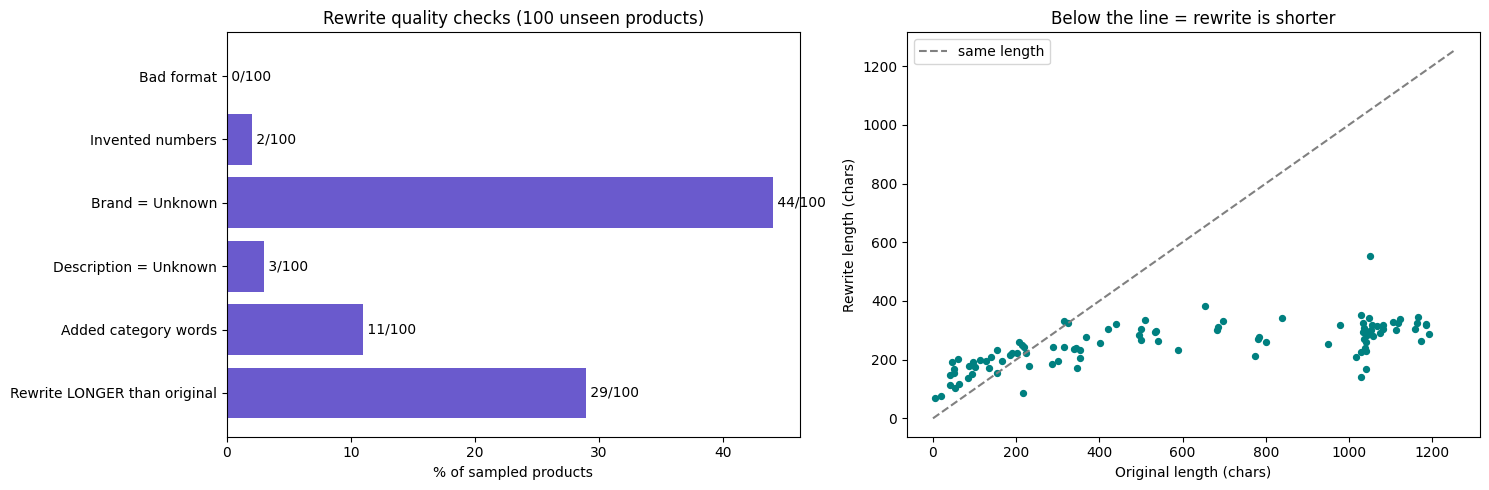

In [10]:
# Cell 8: automatic checks, charts, and cost projection
import matplotlib.pyplot as plt

FIELDS = ["Title", "Brand", "Description", "Details"]
STOP = {"and", "the", "for", "with"}
BATCH_INPUT_PRICE, BATCH_OUTPUT_PRICE = 0.05, 0.20   # gpt-4.1-nano Batch API, USD per 1M tokens (check pricing page)

def field(summary: str, name: str) -> str:
    m = re.search(rf"^{name}:\s*(.*)$", summary, re.M)
    return m.group(1).strip() if m else ""

def good_format(summary: str) -> bool:
    lines = [l for l in summary.strip().splitlines() if l.strip()]
    return len(lines) == 4 and all(field(summary, f) for f in FIELDS)

def words(text: str) -> set:
    """Lowercase words of 3+ letters, crude singular form (bags -> bag)."""
    return {w.rstrip("s") for w in re.findall(r"[a-z]+", text.lower()) if len(w) >= 3} - STOP

def leaked_label_words(label: str, original: str, summary: str) -> set:
    return (words(label) & words(summary)) - words(original)

rows = []
for pid in tqdm(sample_ids, desc="Checking rewrites", unit="product"):
    if pid not in sample_results:
        continue
    summary, tin, tout = sample_results[pid]
    original, label = df.loc[pid, "text"], df.loc[pid, "label"]
    rows.append({
        "id": pid, "label": label, "summary": summary, "in": tin, "out": tout,
        "format_ok": good_format(summary),
        "invented_numbers": invented_numbers(original, summary),
        "brand_unknown": field(summary, "Brand").lower() == "unknown",
        "desc_unknown": field(summary, "Description").lower() == "unknown",
        "leaked": leaked_label_words(label, original, summary),
        "orig_chars": len(original), "new_chars": len(summary),
    })
chk = pd.DataFrame(rows)
n = len(chk)

rates = {
    "Bad format": (~chk["format_ok"]).sum(),
    "Invented numbers": (chk["invented_numbers"].apply(len) > 0).sum(),
    "Brand = Unknown": chk["brand_unknown"].sum(),
    "Description = Unknown": chk["desc_unknown"].sum(),
    "Added category words": (chk["leaked"].apply(len) > 0).sum(),
    "Rewrite LONGER than original": (chk["new_chars"] > chk["orig_chars"]).sum(),
}
print(f"Checks on {n} unseen products:")
for k, v in rates.items():
    print(f"  {k:30} {v:>3} / {n}  ({v / n:.0%})")
print(f"\nLength: median {chk['orig_chars'].median():.0f} -> {chk['new_chars'].median():.0f} chars "
      f"({1 - chk['new_chars'].median() / chk['orig_chars'].median():.0%} shorter)")

# Read the flagged examples (always read real rows)
for title, mask in [("INVENTED NUMBERS", chk["invented_numbers"].apply(len) > 0),
                    ("ADDED CATEGORY WORDS", chk["leaked"].apply(len) > 0)]:
    print(f"\n===== {title}: first 3 =====")
    for _, r in chk[mask].head(3).iterrows():
        extra = r["invented_numbers"] if title.startswith("INVENTED") else r["leaked"]
        print(f"id={r['id']} | label: {r['label']} | flagged: {extra}")
        print(f"  ORIGINAL: {df.loc[r['id'], 'text'][:160]!r}")
        print(f"  REWRITE:  {r['summary'][:220]!r}")

# Cost: actual batch tokens -> projection for all products
tin, tout = chk["in"].sum(), chk["out"].sum()
cost = (tin * BATCH_INPUT_PRICE + tout * BATCH_OUTPUT_PRICE) / 1_000_000
print(f"\nBatch cost for {n}: {tin:,} in / {tout:,} out tokens = ${cost:.4f}")
print(f"Projected for all {len(df):,} products: ${cost / n * len(df):.2f}")

# Charts
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(list(rates.keys()), [v / n * 100 for v in rates.values()], color="slateblue")
for i, v in enumerate(rates.values()):
    axes[0].text(v / n * 100, i, f" {v}/{n}", va="center")
axes[0].invert_yaxis()
axes[0].set_xlabel("% of sampled products")
axes[0].set_title(f"Rewrite quality checks ({n} unseen products)")

axes[1].scatter(chk["orig_chars"], chk["new_chars"], s=18, color="teal")
lim = max(chk["orig_chars"].max(), chk["new_chars"].max()) * 1.05
axes[1].plot([0, lim], [0, lim], "--", color="gray", label="same length")
axes[1].set_xlabel("Original length (chars)")
axes[1].set_ylabel("Rewrite length (chars)")
axes[1].set_title("Below the line = rewrite is shorter")
axes[1].legend()
plt.tight_layout()
plt.show()


### Step 4 findings (100 unseen products)
- **Format OK 100/100.** Safe to train on.
- **"Invented numbers 2/100" were false alarms from MY checker:** the LLM wrote `105931` as `105,931` (thousands comma), and the checker read it as the decimal `105.931`.
  The checker had the same comma ambiguity as the OCB `12,5` bug, in reverse. **Validators need validating too.** Fixed below: compare digits only.
- **"Added category words 11/100" were translation, not leakage:** Portuguese *Jardinagem* -> "garden", German *Bettgestell* -> "bed frame".
  The information was already in the original, just in another language. Leakage means information the input can't support;
  translation makes existing information readable, which is the main *benefit* of rewriting. Word matching can't tell the two apart.
- **Portuguese** is present too: 5 languages (es, fr, de, it, pt).
- **Brand = Unknown 44%:** many listings have no brand (e.g. a steel duct adapter). Not verifiable without brand labels; brand isn't the target.
- **Description = Unknown 3%:** genuinely empty listings, honestly reported.
- **Length:** median 522 -> 260 chars (50% shorter), roughly 146 -> 60 tokens. But **29% got longer**: short listings grow because of the 4-line template.
- Minor: a vehicle VIN was kept despite the "remove IDs" rule. Harmless for classification.
- **Projected cost for all 25,022 products: $0.75.** Decision: prompt v2 is good enough; run the full dataset.

In [11]:
# Cell 8b: fix the number checker (compare digits only) and re-check. No new API calls.
def numbers_in(text: str) -> set:
    """Numbers as digit strings, ignoring separators: '105,931' -> '105931', '12,5' and '12.5' -> '125'.
    Trade-off: '1.25' and '12.5' look the same. Rare, and far better than false alarms."""
    return {re.sub(r"[.,]", "", n) for n in re.findall(r"\d[\d.,]*\d|\d", text)}

# Sanity checks on the cases we know
assert invented_numbers("Odometer 105931 mi", "105,931 miles") == set()          # thousands comma: not invented
assert invented_numbers("12,5 cm", "12.5 cm") == set()                           # decimal comma: not invented
assert invented_numbers("12,5 cm 11,5 cm 5,5 cm", "quantity of 12 sheets") == {"12"}   # the real OCB hallucination
print("Checker sanity tests passed")

chk["invented_numbers"] = [invented_numbers(df.loc[i, "text"], s) for i, s in zip(chk["id"], chk["summary"])]
print(f"Invented numbers after the fix: {(chk['invented_numbers'].apply(len) > 0).sum()} / {len(chk)}")


Checker sanity tests passed
Invented numbers after the fix: 1 / 100


## Step 5: The full run (all 25,022 products)

Same Batch API flow, scaled up, following the course's full-run design (cells 29 to 33):
- **Chunks of 4,000 requests.** OpenAI limits how many tokens can be *queued* at once per model. At ~360 tokens per request,
  4,000 requests is ~1.5M tokens, safely under a typical 2M limit. Chunks run one after another.
- **Resumable at two levels:** a chunk whose results are already downloaded is skipped; a chunk already submitted is reused
  via its saved batch id. Re-running after a crash never pays twice.
- **Safety assert:** the notebook stops if any product lacks a summary, so an incomplete dataset can never be published.

Expect this to take a while (each chunk is a separate batch). You can leave it running; progress bars show where it is.

In [12]:
# Cell 9: run all products through the Batch API in resumable chunks
CHUNK_SIZE = 4_000
all_ids = df["id"].tolist()
chunks = [all_ids[i:i + CHUNK_SIZE] for i in range(0, len(all_ids), CHUNK_SIZE)]
print(f"{len(all_ids):,} products -> {len(chunks)} chunks of up to {CHUNK_SIZE:,}")

summaries = {}
for k, ids in enumerate(tqdm(chunks, desc="Chunks", unit="chunk")):
    name = f"full_{k:02d}"
    request_file = BATCH_DIR / f"{name}.jsonl"
    result_file = BATCH_DIR / f"{name}_results.jsonl"
    state = BATCH_DIR / f"{name}_batch.json"

    if result_file.exists():
        print(f"{name}: results already downloaded, reusing")
    else:
        if state.exists():
            batch_id = json.loads(state.read_text())["batch_id"]
            print(f"{name}: reusing submitted batch {batch_id}")
        else:
            write_jsonl(ids, request_file)
            batch_id = submit_batch(request_file).id
            state.write_text(json.dumps({"batch_id": batch_id}))
            print(f"{name}: submitted batch {batch_id}")
        b = wait_for_batch(batch_id)
        report_errors(b)
        if not download_results(b, result_file):
            print(f"Stopping at {name}. Fix the error above and re-run this cell; finished chunks are skipped.")
            break
    summaries.update(read_results(result_file))

print(f"\nSummaries collected: {len(summaries):,} / {len(all_ids):,}")


25,022 products -> 7 chunks of up to 4,000


Chunks:   0%|          | 0/7 [00:00<?, ?chunk/s]

Writing full_00.jsonl:   0%|          | 0/4000 [00:00<?, ?request/s]

full_00: submitted batch [batch_id]


Batch progress: 0request [00:00, ?request/s]

...

Writing full_06.jsonl:   0%|          | 0/1022 [00:00<?, ?request/s]

full_06: submitted batch [batch_id]


Batch progress: 0request [00:00, ?request/s]

Reading full_06_results.jsonl: 0line [00:00, ?line/s]

Parsed 1022 results, 0 failed

Summaries collected: 25,022 / 25,022


In [13]:
# Cell 10: attach summaries to the products + safety assert + total cost
df["summary"] = df["id"].map(lambda i: summaries[i][0] if i in summaries else None)
df["summary_in_tokens"] = df["id"].map(lambda i: summaries[i][1] if i in summaries else 0)
df["summary_out_tokens"] = df["id"].map(lambda i: summaries[i][2] if i in summaries else 0)

missing = df["summary"].isna().sum()
print(f"Products without a summary: {missing}")
assert missing == 0, f"{missing} products have no summary. Re-run cell 9 before continuing."

tin, tout = df["summary_in_tokens"].sum(), df["summary_out_tokens"].sum()
total_cost = (tin * BATCH_INPUT_PRICE + tout * BATCH_OUTPUT_PRICE) / 1_000_000
print(f"Total: {tin:,} input + {tout:,} output tokens = ${total_cost:.2f}")


Products without a summary: 0
Total: 9,149,712 input + 1,555,136 output tokens = $0.77


## Step 6: Quality checks on ALL rewrites

The same automatic checks as the 100-product sample (with the fixed number checker), now on every product.
At 25,022 rows, reading by eye is impossible: this is where automatic checks earn their keep.

Checking all rewrites:   0%|          | 0/25022 [00:00<?, ?product/s]

Checks on all 25,022 products:
  Bad format                                     52  (0.2%)
  Invented numbers                              374  (1.5%)
  Brand = Unknown                            11,575  (46.3%)
  Description = Unknown                         391  (1.6%)
  Added category words (mostly translation)   1,554  (6.2%)
  Rewrite longer than original                5,982  (23.9%)

Length: median 575 -> 265 chars
Output tokens per summary: median 62

id=164 | flagged: {'2018', '2024'}
  ORIGINAL: 'R-TECH BLACK TANK COVER YAMAHA YZ450F 18-22 YZ450FX 19-23 WR450F 19-24\nMajority of our listings are for a direct replacement for your original part. Our parts a'
  REWRITE:  'Title: R-Tech Black Tank Cover for Yamaha YZ450F/YZ450FX/WR450F  \nBrand: R-Tech  \nDescription: Replacement tank cover for Yamaha YZ450F, YZ450FX, and WR450F motorcycles.  \nDetails: Made of quality material, designed to m'

id=364 | flagged: {'50'}
  ORIGINAL: 'GamerFinger 30mm サクラ/ブラック\nアーケードコントローラー用30mm、はめ込

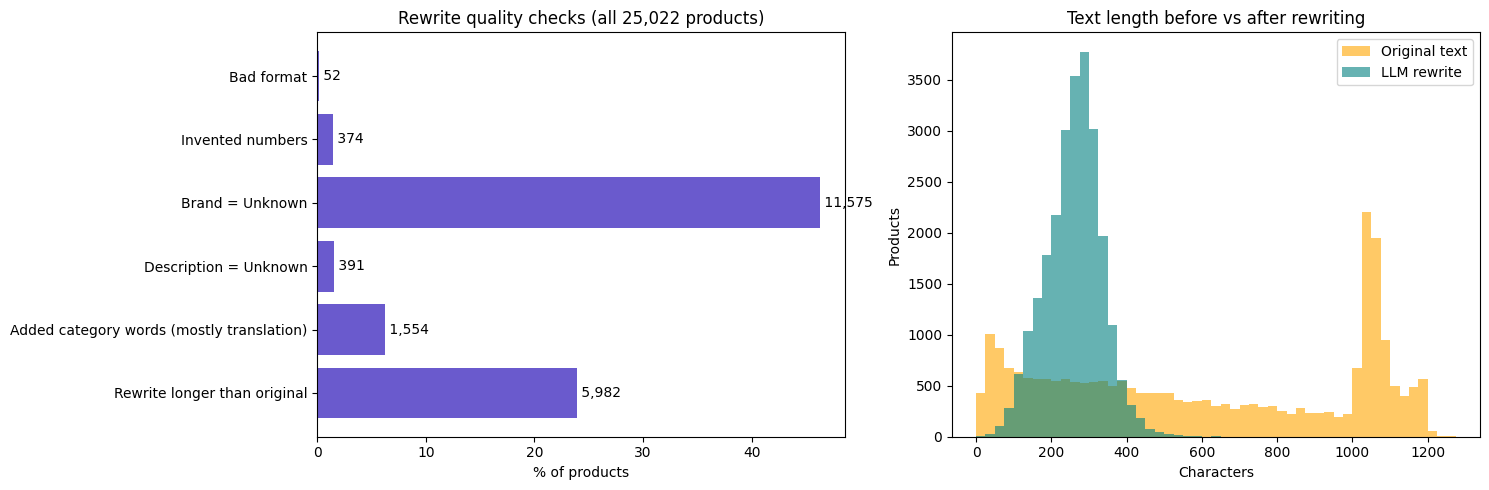


Saved data/rewritten.parquet


In [14]:
# Cell 11: run every check on all 25,022 rewrites, chart the results, save locally
def run_checks(frame: pd.DataFrame) -> pd.DataFrame:
    out = []
    for _, r in tqdm(frame.iterrows(), total=len(frame), desc="Checking all rewrites", unit="product"):
        s, t = r["summary"], r["text"]
        out.append({
            "id": r["id"],
            "format_ok": good_format(s),
            "invented": bool(invented_numbers(t, s)),
            "brand_unknown": field(s, "Brand").lower() == "unknown",
            "desc_unknown": field(s, "Description").lower() == "unknown",
            "added_label_words": bool(leaked_label_words(r["label"], t, s)),
            "longer": len(s) > len(t),
            "orig_chars": len(t), "new_chars": len(s),
        })
    return pd.DataFrame(out)

full_chk = run_checks(df)
N = len(full_chk)
full_rates = {
    "Bad format": (~full_chk["format_ok"]).sum(),
    "Invented numbers": full_chk["invented"].sum(),
    "Brand = Unknown": full_chk["brand_unknown"].sum(),
    "Description = Unknown": full_chk["desc_unknown"].sum(),
    "Added category words (mostly translation)": full_chk["added_label_words"].sum(),
    "Rewrite longer than original": full_chk["longer"].sum(),
}
print(f"Checks on all {N:,} products:")
for k, v in full_rates.items():
    print(f"  {k:42} {v:>6,}  ({v / N:.1%})")
print(f"\nLength: median {full_chk['orig_chars'].median():.0f} -> {full_chk['new_chars'].median():.0f} chars")
print(f"Output tokens per summary: median {df['summary_out_tokens'].median():.0f}")

# Read some real invented-number cases (if any)
bad = full_chk[full_chk["invented"]].head(3)
for _, r in bad.iterrows():
    print(f"\nid={r['id']} | flagged: {invented_numbers(df.loc[r['id'], 'text'], df.loc[r['id'], 'summary'])}")
    print(f"  ORIGINAL: {df.loc[r['id'], 'text'][:160]!r}")
    print(f"  REWRITE:  {df.loc[r['id'], 'summary'][:220]!r}")

# Charts: check rates + length distribution before/after
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(list(full_rates.keys()), [v / N * 100 for v in full_rates.values()], color="slateblue")
for i, v in enumerate(full_rates.values()):
    axes[0].text(v / N * 100, i, f" {v:,}", va="center")
axes[0].invert_yaxis()
axes[0].set_xlabel("% of products")
axes[0].set_title(f"Rewrite quality checks (all {N:,} products)")
axes[1].hist(full_chk["orig_chars"], bins=range(0, 1300, 25), alpha=0.6, color="orange", label="Original text")
axes[1].hist(full_chk["new_chars"], bins=range(0, 1300, 25), alpha=0.6, color="teal", label="LLM rewrite")
axes[1].set_xlabel("Characters")
axes[1].set_ylabel("Products")
axes[1].set_title("Text length before vs after rewriting")
axes[1].legend()
plt.tight_layout()
plt.show()

# Save locally (data/ is gitignored); publishing comes next
Path("data").mkdir(exist_ok=True)
df[["text", "summary", "label", "full_category", "split", "id"]].to_parquet("data/rewritten.parquet", index=False)
print("\nSaved data/rewritten.parquet")


### Step 5-6 findings (full run, all 25,022 products)
- **7 batches, 0 failed requests, every product got a summary.** Total cost **$0.77** (9.1M input + 1.6M output tokens).
- Median length **575 -> 265 chars** (54% shorter), median **62 output tokens** per summary.
- **Bad format: 52 (0.2%).** Must be fixed before training.
- **Invented numbers: 374 (1.5%) is an upper bound.** The 3 cases read were conversions, not inventions:
  short years expanded (`18-24` -> `2018-2024`), Japanese **full-width digits** (`５０` vs `50`), and unit conversions (`1歳半` -> 1.5 years).
- **Japanese is in the data.** The Day 1 language heuristic only looked for English/Spanish words, so it couldn't see it. At least 6 languages.
- Description = Unknown 1.6%, Brand = Unknown 46%, added category words 6.2% (mostly translation), longer than original 24%.

## Step 7: Measure how often the number checker is right

1. **Normalise full-width characters** with Unicode NFKC (`５０` -> `50`), a standard text-cleaning step for East Asian text.
2. **Read 20 flagged products by hand** and label each: *invented* (a fact the original doesn't support) or *conversion* (years expanded, units converted, formatting).

Step 2 measures the checker's **precision**: of the products it flags, how many are real problems?
When an automatic check is imperfect, you don't just trust or ignore it: you measure it on a small hand-labelled sample.

In [15]:
# Cell 12: NFKC fix for full-width digits, re-check all products, print 20 flagged cases to label by hand
import unicodedata

def numbers_in(text: str) -> set:
    """Digit strings, ignoring separators, after NFKC normalisation (full-width '５０' -> '50')."""
    text = unicodedata.normalize("NFKC", text)
    return {re.sub(r"[.,]", "", n) for n in re.findall(r"\d[\d.,]*\d|\d", text)}

# Lock in every case we know about
assert invented_numbers("Odometer 105931 mi", "105,931 miles") == set()
assert invented_numbers("12,5 cm", "12.5 cm") == set()
assert invented_numbers("12,5 cm 11,5 cm 5,5 cm", "quantity of 12 sheets") == {"12"}
assert invented_numbers("押下圧：４５ｇ　５０ｍｍ", "45g, 50mm") == set()        # full-width digits
print("Checker sanity tests passed (4/4)")

before = full_chk["invented"].sum()
full_chk["invented"] = [bool(invented_numbers(df.loc[i, "text"], df.loc[i, "summary"]))
                        for i in tqdm(full_chk["id"], desc="Re-checking numbers", unit="product")]
after = full_chk["invented"].sum()
print(f"Flagged for invented numbers: {before:,} -> {after:,} after NFKC ({after / len(full_chk):.1%})")

# 20 random flagged products to label by hand
def context(text: str, num: str, width: int = 45) -> str:
    """Show the text around the first occurrence of a flagged number."""
    norm = unicodedata.normalize("NFKC", text)
    for m in re.finditer(r"\d[\d.,]*\d|\d", norm):
        if re.sub(r"[.,]", "", m.group()) == num:
            return "..." + norm[max(0, m.start() - width): m.end() + width].replace("\n", " ") + "..."
    return "(not found)"

review = full_chk[full_chk["invented"]].sample(20, random_state=1)
for k, pid in enumerate(review["id"], 1):
    text, summary = df.loc[pid, "text"], df.loc[pid, "summary"]
    flagged = invented_numbers(text, summary)
    print(f"\n#{k:02d} id={pid} | flagged: {flagged}")
    print(f"   ORIGINAL: {unicodedata.normalize('NFKC', text)[:200].replace(chr(10), ' ')!r}")
    for num in list(flagged)[:2]:
        print(f"   REWRITE around {num}: {context(summary, num)}")


Checker sanity tests passed (4/4)


Re-checking numbers:   0%|          | 0/25022 [00:00<?, ?product/s]

Flagged for invented numbers: 374 -> 358 after NFKC (1.4%)

#01 id=19317 | flagged: {'037'}
   ORIGINAL: 'KOLO KOLO Bath Brush Bambu 2 The KOLO Bambu Bath Brush 2 is a thoughtfully designed sauna brush with a long bamboo handle that lets you exfoliate hard-to-reach areas. Bamboo wood was selected for its '
   REWRITE around 037: ...ylene bristles, 15.74" (40cm) long, weighing 0.37 lbs (167 g)....

#02 id=16445 | flagged: {'16', '13'}
   ORIGINAL: 'Waterslide Inflatable Lake Slide Backyard Blast Water Pool Big Tall Little Jumper Experience backyard bliss with our Waterslide Inflatable Lake Slide! Perfect for lakeside fun, this blast of excitemen'
   REWRITE around 16: ...VC+0.6mm PVC, measures 8 x 4 x 5M (26 x 13 x 16 ft), with free shipping and a 2-year warrant...
   REWRITE around 13: ...5mm PVC+0.6mm PVC, measures 8 x 4 x 5M (26 x 13 x 16 ft), with free shipping and a 2-year wa...

#03 id=22862 | flagged: {'16'}
   ORIGINAL: 'Wet Mop Loop: Clamp Jaw, Large, Gray Mop, Microfiber Item 

## Step 8: Diagnose the 52 bad-format rewrites

Before fixing, find out *why* they failed. Retrying blindly is a trap here: with `temperature=0` the model gives
(almost) the same answer to the same input, so an identical retry usually fails the same way.
The cause decides the fix:
- **Cut off** (no `Details:` line, long answer): raise `max_tokens`.
- **Extra lines / commentary:** retry with a stricter instruction or a little randomness.
- **Refusal or junk input:** fall back to the original text.

In [16]:
# Cell 13: why did 52 rewrites fail the format check?
bad = full_chk.loc[~full_chk["format_ok"], "id"].tolist()
print(f"Bad-format rewrites: {len(bad)}")

def diagnose(summary: str, out_tokens: int) -> str:
    lines = [l for l in summary.strip().splitlines() if l.strip()]
    present = [f for f in FIELDS if field(summary, f)]
    if out_tokens >= MAX_TOKENS - 2:
        return "cut off at max_tokens"
    if len(present) < 4:
        return f"missing field(s): {sorted(set(FIELDS) - set(present))}"
    if len(lines) > 4:
        return "extra lines"
    return "other"

df_bad = df.set_index("id").loc[bad]
reasons = pd.Series([diagnose(s, t) for s, t in zip(df_bad["summary"], df_bad["summary_out_tokens"])], index=bad)
print("\nReasons:")
print(reasons.value_counts().to_string())

for reason in reasons.unique():
    pid = reasons[reasons == reason].index[0]
    print(f"\n===== Example: {reason} (id={pid}) =====")
    print(f"ORIGINAL: {df.loc[pid, 'text'][:200]!r}")
    print(f"REWRITE ({df.loc[pid, 'summary_out_tokens']} tokens):")
    print(df.loc[pid, "summary"])


Bad-format rewrites: 52

Reasons:
missing field(s): ['Brand', 'Title']               42
missing field(s): ['Title']                         4
extra lines                                         3
missing field(s): ['Brand', 'Details', 'Title']     3

===== Example: missing field(s): ['Title'] (id=22) =====
ORIGINAL: 'Melody Dixie\nDahlia is a genus of bushy, tuberous perennial plants native to Mexico and Central America. These popular garden flowers are prized for their spectacular blooms, which come in an extraord'
REWRITE (12 tokens):
Description: Unknown  
Brand: Melody Dixie  
Details: Unknown

===== Example: missing field(s): ['Brand', 'Title'] (id=459) =====
ORIGINAL: 'The Surveying Handbook\nThe first edition of The Surveying Handbook, although a ground breaker, was widely accepted. However, surveying is a dynamic profession with each new development just one step a'
REWRITE (7 tokens):
Description: Unknown  
Details: Unknown

===== Example: extra lines (id=898) =====
ORIGINAL: 

### Step 7-8 findings

**Number checker precision (20 flagged products read by hand):**
- ~10 were **conversions or translations** (167 g -> 0.37 lbs, 6.30 bar -> 90 psi, "zwei Zentimeter" -> 2 cm, "12-18" -> 2012 to 2018). Fine.
- ~4-5 look **invented**, and not randomly: the model filled in specs **from its own memory** (a workbench's 4,500 lb capacity, a shelf's 800 lb).
  Possibly true, but not in the listing, so not grounded.
- ~4 unclear, likely formatting (`6%` vs `6.0%`).
- Precision ~20-25%, so the realistic hallucination rate is ~1.4% x 25% = **~0.35% of products**.

**Bad format (52):**
- 49 skipped fields and wrote `Description: Unknown` for products **with** real descriptions (a surveying handbook, a book on credit cards, a dahlia).
  Cause: **the v2 rule written for "Marriage" was over-applied**, especially to books and plants. v2 was tested on 5 products, none of them a book.
  Every prompt fix has side effects.
- 3 listings contained **two products**; the model correctly wrote two blocks. A data issue.
- This means the earlier claim "Description = Unknown = genuinely empty listings" was **wrong** for some. Measured below.

**Decision:** prompt v3, validated on a regression set, then **re-run all products with v3** ($0.77) rather than patching a subset.
Patching would leave a dataset made by two prompts, while new products would only ever see v3: a train/serve mismatch.

## Step 9: How many "Description: Unknown" were false?

A product is a **false Unknown** if its listing has a real description (a second line) and over 150 characters, yet the rewrite said Unknown.

Description = Unknown:            391
  ...with a real description:      73  <- false Unknowns (over-caution)
  ...genuinely short listings:     318
Bad format:                       52
Affected products to fix with v3: 88


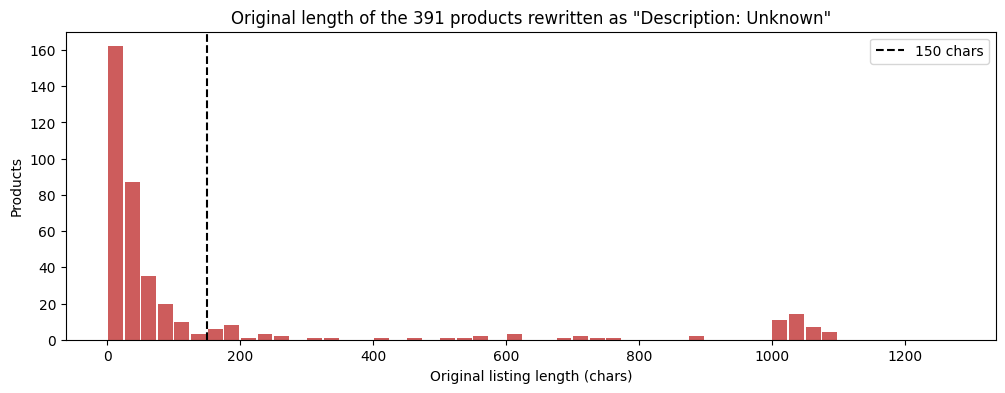


id=22 | label: Home & Garden > Plants
  ORIGINAL: 'Melody Dixie\nDahlia is a genus of bushy, tuberous perennial plants native to Mexico and Central America. These popular garden flowers are prized for their spectacular blooms, which'
  REWRITE:  'Description: Unknown  \nBrand: Melody Dixie  \nDetails: Unknown'

id=177 | label: Business & Industrial > Retail
  ORIGINAL: 'Thales Talento T-One 540.319.756/14 540-319 (7.5.3)\nThales Talento T-One 540.319.756/14 540-319 Palmetto Automation Inc. of Duncan SC specializes in buying, selling, and repairing '
  REWRITE:  'Title: Thales Talento T-One 540-319\nBrand: Thales\nDescription: Unknown\nDetails: Unknown'

id=459 | label: Business & Industrial > Construction
  ORIGINAL: 'The Surveying Handbook\nThe first edition of The Surveying Handbook, although a ground breaker, was widely accepted. However, surveying is a dynamic profession with each new develop'
  REWRITE:  'Description: Unknown  \nDetails: Unknown'


In [17]:
# Cell 14: measure false "Description: Unknown"
unknown_ids = full_chk.loc[full_chk["desc_unknown"], "id"]
u_text = df.loc[unknown_ids, "text"]
false_unknown = unknown_ids[(u_text.str.len() > 150) & u_text.str.contains("\n")].tolist()
bad_format = full_chk.loc[~full_chk["format_ok"], "id"].tolist()

print(f"Description = Unknown:            {len(unknown_ids):,}")
print(f"  ...with a real description:      {len(false_unknown):,}  <- false Unknowns (over-caution)")
print(f"  ...genuinely short listings:     {len(unknown_ids) - len(false_unknown):,}")
print(f"Bad format:                       {len(bad_format):,}")
affected = sorted(set(false_unknown) | set(bad_format))
print(f"Affected products to fix with v3: {len(affected):,}")

plt.figure(figsize=(12, 4))
plt.hist(u_text.str.len(), bins=range(0, 1300, 25), color="indianred", rwidth=0.9)
plt.axvline(150, color="black", linestyle="--", label="150 chars")
plt.title(f'Original length of the {len(unknown_ids)} products rewritten as "Description: Unknown"')
plt.xlabel("Original listing length (chars)"); plt.ylabel("Products"); plt.legend()
plt.show()

for pid in false_unknown[:3]:
    print(f"\nid={pid} | label: {df.loc[pid, 'label']}")
    print(f"  ORIGINAL: {df.loc[pid, 'text'][:180]!r}")
    print(f"  REWRITE:  {df.loc[pid, 'summary']!r}")


## Step 10: Prompt v3 and a regression test

Changes from v2 (each tied to an observed failure):
1. **Always write all four lines; Title is never Unknown.** (Fields were skipped.)
2. **`Description: Unknown` only when the listing is just a few words with no description.** Books, media, plants and services must be described. (Over-applied v2 rule.)
3. **If the listing contains several items, describe only the first.** (Two-product listings.)

**Regression test** on three groups, comparing v2 with v3:
| Group | Question |
|---|---|
| Affected products | Did v3 fix them? |
| 100-product sample | Is v3 at least as good as v2 on ordinary products? |
| 5 tuning products | Do the earlier fixes still hold ("Marriage" Unknown, OCB brand, no "12 sheets")? |

Run as normal API calls, 8 in parallel, because it's a few hundred products and we want the answer in minutes.

In [18]:
# Cell 15: prompt v3 + regression test against v2
from concurrent.futures import ThreadPoolExecutor, as_completed

SYSTEM_PROMPT_V3 = """You rewrite e-commerce product listings into a short, standard format.
Respond in English, in exactly this format and nothing else:
Title: short, precise product title
Brand: the brand name if it appears in the listing (often the first word of the title), otherwise Unknown
Description: one sentence on what the product is
Details: one sentence on key features (material, size, colour, quantity), or Unknown

Rules:
- Always write all four lines, in this order. Title is never Unknown: use the product name from the listing.
- Use only information in the listing. Never invent facts, and do not add specifications from your own knowledge.
- Write "Description: Unknown" only when the listing is just a few words with no description at all.
  If the listing has any descriptive text (including books, media, plants and services), describe it.
- If the listing contains several items, describe only the first one.
- Copy numbers and units exactly as written. A comma may be a decimal separator (12,5 cm means 12.5 cm).
  Never turn a measurement into a quantity.
- Do not mention the product's category or store department.
- Remove part numbers, SKUs, prices, URLs, contact details and marketing slogans.
- If the listing is not in English, translate it into English."""

def run_parallel(prompt: str, ids, workers: int = 8) -> dict:
    """id -> (summary, in_tokens, out_tokens), using normal API calls in parallel."""
    out, errors = {}, 0
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futures = {ex.submit(rewrite_with, prompt, df.loc[i, "text"]): i for i in ids}
        for f in tqdm(as_completed(futures), total=len(futures), desc="Rewriting with v3", unit="product"):
            try:
                out[futures[f]] = f.result()
            except Exception as e:
                errors += 1
                print(f"  error on id={futures[f]}: {e}")
    if errors:
        print(f"{errors} errors")
    return out

groups = {
    "Affected (bad format + false Unknown)": affected,
    "100-product sample": list(sample_ids),
    "5 tuning products": list(picks.values()),
}
v3_ids = sorted(set().union(*groups.values()))
v3_out = run_parallel(SYSTEM_PROMPT_V3, v3_ids)

def metrics(ids, summary_of) -> dict:
    ids = [i for i in ids if summary_of(i)]
    s = {i: summary_of(i) for i in ids}
    n = len(ids)
    return {
        "n": n,
        "format OK": sum(good_format(s[i]) for i in ids) / n,
        "Description=Unknown": sum(field(s[i], "Description").lower() == "unknown" for i in ids) / n,
        "Brand=Unknown": sum(field(s[i], "Brand").lower() == "unknown" for i in ids) / n,
        "invented numbers": sum(bool(invented_numbers(df.loc[i, "text"], s[i])) for i in ids) / n,
        "median chars": float(pd.Series([len(s[i]) for i in ids]).median()),
    }

table = []
for gname, ids in groups.items():
    table.append({"group": gname, "prompt": "v2", **metrics(ids, lambda i: df.loc[i, "summary"])})
    table.append({"group": gname, "prompt": "v3", **metrics(ids, lambda i: v3_out.get(i, (None,))[0])})
report = pd.DataFrame(table)
pct_cols = ["format OK", "Description=Unknown", "Brand=Unknown", "invented numbers"]
print(report.to_string(index=False, formatters={c: "{:.1%}".format for c in pct_cols}))

# Read the known problem cases: v2 vs v3
for pid in [459, 6933, 22, 898, 0, 10214]:
    if pid in v3_out:
        print("=" * 90)
        print(f"id={pid} | label: {df.loc[pid, 'label']}")
        print(f"ORIGINAL: {df.loc[pid, 'text'][:150]!r}")
        print(f"--- v2 ---\n{df.loc[pid, 'summary']}")
        print(f"--- v3 ---\n{v3_out[pid][0]}")

tin = sum(v[1] for v in v3_out.values()); tout = sum(v[2] for v in v3_out.values())
print(f"\nv3 test cost: ${(tin * INPUT_PRICE + tout * OUTPUT_PRICE) / 1_000_000:.4f} for {len(v3_out)} products")


Rewriting with v3:   0%|          | 0/192 [00:00<?, ?product/s]

                                group prompt   n format OK Description=Unknown Brand=Unknown invented numbers  median chars
Affected (bad format + false Unknown)     v2  88     40.9%               83.0%         12.5%             2.3%          92.0
Affected (bad format + false Unknown)     v3  88     95.5%               27.3%         59.1%             2.3%         220.5
                   100-product sample     v2 100    100.0%                3.0%         44.0%             1.0%         252.5
                   100-product sample     v3 100    100.0%                3.0%         45.0%             2.0%         268.0
                    5 tuning products     v2   5    100.0%               20.0%         20.0%             0.0%         203.0
                    5 tuning products     v3   5    100.0%               20.0%         20.0%             0.0%         300.0
id=459 | label: Business & Industrial > Construction
ORIGINAL: 'The Surveying Handbook\nThe first edition of The Surveying Handbook,

### Step 10 findings (v3 regression test, 192 products, $0.013)

| Group | v2 | v3 |
|---|---|---|
| Affected (88): format OK | 40.9% | **95.5%** |
| Affected: Description = Unknown | 83.0% | **27.3%** |
| 100 ordinary: format / Unknown / Brand Unknown | 100% / 3% / 44% | 100% / 3% / 45% |
| 100 ordinary: invented numbers | 1% | 2% (1 extra product, read below) |
| 5 tuning: "Marriage" | Unknown | Unknown |
| 5 tuning: OCB brand | OCB | **"OC B"** (small regression) |

- **"Describe only the first item" was ignored:** Harken still produced two blocks. Structural rules belong in **code**, which can guarantee them; prompts can only request.
- **"Don't add from your own knowledge" was partly ignored:** "a Torlon ball used for sailing" (not in the listing).
- **Label noise:** Harken sailing balls are labelled `Electronics > Arcade Equipment`. Some labels are simply wrong.
- Decision: adopt v3, enforce the structure in code with `clean_summary()`, re-run all products.

## Step 11: Pre-flight checks before the full v3 run

1. Read the extra "invented number" product from the 100-sample (v3 flagged it, v2 didn't).
2. `clean_summary()`: deterministic post-processing in **code**:
   - keep only the **first** Title / Brand / Description / Details block (two-product listings),
   - fill a missing Title from the listing's first line, and other missing fields with `Unknown`,
   - strip trailing spaces.
   Tested on the real failure cases, then applied to the v3 test outputs to confirm format OK reaches 100%.

In [19]:
# Cell 16: read the new flagged case + clean_summary() in code, with tests
# 1) The product v3 flagged for invented numbers but v2 didn't
new_flags = [i for i in sample_ids
             if invented_numbers(df.loc[i, "text"], v3_out[i][0])
             and not invented_numbers(df.loc[i, "text"], df.loc[i, "summary"])]
for pid in new_flags:
    print(f"id={pid} | flagged: {invented_numbers(df.loc[pid, 'text'], v3_out[pid][0])}")
    print(f"  ORIGINAL: {df.loc[pid, 'text'][:250]!r}")
    print(f"  v3:       {v3_out[pid][0]!r}\n")

# 2) Enforce the 4-line structure in code
LINE = re.compile(r"^\s*(Title|Brand|Description|Details)\s*:\s*(.*?)\s*$")

def clean_summary(summary: str, original: str) -> str:
    """Keep the first value of each field, in a fixed order. Missing Title -> listing's first line."""
    kept = {}
    for line in summary.splitlines():
        m = LINE.match(line)
        if m and m.group(1) not in kept and m.group(2):
            kept[m.group(1)] = m.group(2)
    if "Title" not in kept:
        kept["Title"] = original.splitlines()[0].strip()[:120]
    return "\n".join(f"{f}: {kept.get(f, 'Unknown')}" for f in FIELDS)

# Tests built from the real failures
harken = v3_out[898][0]
assert clean_summary(harken, df.loc[898, "text"]).count("Title:") == 1                      # two products -> first only
assert clean_summary("Description: Unknown  \nBrand: Melody Dixie  \nDetails: Unknown",
                     "Melody Dixie\nDahlia is a genus...").splitlines()[0] == "Title: Melody Dixie"  # missing Title filled
assert good_format(clean_summary("Description: Unknown", "Charging Ahead: The Growth...\nThis book..."))  # 1-line output repaired
assert clean_summary("Title: Marriage  \nBrand: Unknown  \nDescription: Unknown  \nDetails: Unknown", "Marriage") \
       == "Title: Marriage\nBrand: Unknown\nDescription: Unknown\nDetails: Unknown"           # good output unchanged (spaces tidied)
print("clean_summary tests passed (4/4)")

# 3) Effect on the v3 test outputs
for gname, ids in groups.items():
    raw_ok = sum(good_format(v3_out[i][0]) for i in ids) / len(ids)
    clean_ok = sum(good_format(clean_summary(v3_out[i][0], df.loc[i, "text"])) for i in ids) / len(ids)
    print(f"{gname:40} format OK: raw v3 {raw_ok:.1%} -> after clean_summary {clean_ok:.1%}")


id=13153 | flagged: {'20', '9'}
  ORIGINAL: 'Ultimate Bootcamp (Friday 9.20 - Intermediate)'
  v3:       'Title: Ultimate Bootcamp (Friday 9.20 - Intermediate)  \nBrand: Unknown  \nDescription: A fitness bootcamp session scheduled for Friday at 9:20 for intermediate participants.  \nDetails: Unknown'

clean_summary tests passed (4/4)
Affected (bad format + false Unknown)    format OK: raw v3 95.5% -> after clean_summary 100.0%
100-product sample                       format OK: raw v3 100.0% -> after clean_summary 100.0%
5 tuning products                        format OK: raw v3 100.0% -> after clean_summary 100.0%


## Step 12: Full re-run with prompt v3 (all 25,022 products)

Same resumable, chunked Batch API loop as Step 5, with the v3 prompt and new file names (`v3full_XX`) so the v2 files are untouched.
`clean_summary()` is applied to every result. The v2 rewrites are kept in a `summary_v2` column for comparison.

In [20]:
# Cell 17: full v3 run through the Batch API (resumable), then clean_summary on every result
def make_request(pid: int, prompt: str = SYSTEM_PROMPT_V3) -> dict:
    """Redefined for v3: write_jsonl() picks this up automatically."""
    body = {"model": MODEL,
            "messages": [{"role": "system", "content": prompt}, {"role": "user", "content": df.loc[pid, "text"]}],
            "max_tokens": MAX_TOKENS, "temperature": 0}
    return {"custom_id": str(pid), "method": "POST", "url": "/v1/chat/completions", "body": body}

summaries_v3 = {}
for k, ids in enumerate(tqdm(chunks, desc="v3 chunks", unit="chunk")):
    name = f"v3full_{k:02d}"
    request_file, result_file = BATCH_DIR / f"{name}.jsonl", BATCH_DIR / f"{name}_results.jsonl"
    state = BATCH_DIR / f"{name}_batch.json"
    if result_file.exists():
        print(f"{name}: results already downloaded, reusing")
    else:
        if state.exists():
            batch_id = json.loads(state.read_text())["batch_id"]
            print(f"{name}: reusing submitted batch {batch_id}")
        else:
            write_jsonl(ids, request_file)
            batch_id = submit_batch(request_file).id
            state.write_text(json.dumps({"batch_id": batch_id}))
            print(f"{name}: submitted batch {batch_id}")
        b = wait_for_batch(batch_id)
        report_errors(b)
        if not download_results(b, result_file):
            print(f"Stopping at {name}. Fix the error above and re-run; finished chunks are skipped.")
            break
    summaries_v3.update(read_results(result_file))

print(f"\nv3 summaries collected: {len(summaries_v3):,} / {len(df):,}")


v3 chunks:   0%|          | 0/7 [00:00<?, ?chunk/s]

Writing v3full_00.jsonl:   0%|          | 0/4000 [00:00<?, ?request/s]

v3full_00: submitted batch [batch_id]


Batch progress: 0request [00:00, ?request/s]

Reading v3full_00_results.jsonl: 0line [00:00, ?line/s]

...

Writing v3full_06.jsonl:   0%|          | 0/1022 [00:00<?, ?request/s]

v3full_06: submitted batch [batch_id]


Batch progress: 0request [00:00, ?request/s]

Reading v3full_06_results.jsonl: 0line [00:00, ?line/s]

Parsed 1022 results, 0 failed

v3 summaries collected: 25,022 / 25,022


## Step 13: Attach v3, safety assert, full checks (v2 vs v3)

clean_summary:   0%|          | 0/25022 [00:00<?, ?product/s]

v3 full run: 10,726,098 in + 1,568,805 out tokens = $0.85
clean_summary changed 19,692 raw outputs (mostly whitespace)


Checking all rewrites:   0%|          | 0/25022 [00:00<?, ?product/s]


All 25,022 products:
                                              v2  v3 + clean_summary   v2 %   v3 %
Bad format                                    52                   0   0.21   0.00
Invented numbers                             374                 434   1.49   1.73
Brand = Unknown                            11575               11723  46.26  46.85
Description = Unknown                        391                 625   1.56   2.50
Added category words (mostly translation)   1554                1773   6.21   7.09
Rewrite longer than original                5982                6094  23.91  24.35

Length: median 575 -> 267 chars


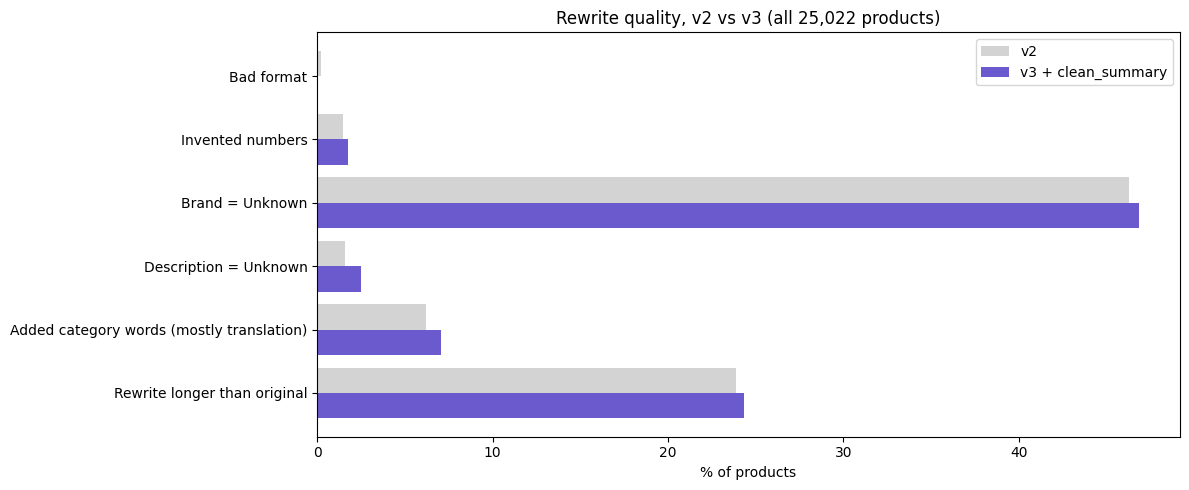

Saved data/rewritten.parquet


In [22]:
# Cell 18: attach cleaned v3 summaries, assert completeness, compare v2 vs v3 on everything, save
import numpy as np
missing = len(df) - len(summaries_v3)
assert missing == 0, f"{missing} products have no v3 summary. Re-run cell 17."

if "summary_v2" not in df.columns:
    df["summary_v2"] = df["summary"]
df["summary_raw_v3"] = df["id"].map(lambda i: summaries_v3[i][0])
df["summary"] = [clean_summary(s, t) for s, t in tqdm(zip(df["summary_raw_v3"], df["text"]),
                                                       total=len(df), desc="clean_summary", unit="product")]
df["summary_in_tokens"] = df["id"].map(lambda i: summaries_v3[i][1])
df["summary_out_tokens"] = df["id"].map(lambda i: summaries_v3[i][2])

tin, tout = df["summary_in_tokens"].sum(), df["summary_out_tokens"].sum()
print(f"v3 full run: {tin:,} in + {tout:,} out tokens = ${(tin * BATCH_INPUT_PRICE + tout * BATCH_OUTPUT_PRICE) / 1e6:.2f}")
print(f"clean_summary changed {(df['summary'] != df['summary_raw_v3'].str.strip()).sum():,} raw outputs (mostly whitespace)")

v2_rates = full_rates
full_chk = run_checks(df)
N = len(full_chk)
v3_rates = {
    "Bad format": (~full_chk["format_ok"]).sum(),
    "Invented numbers": full_chk["invented"].sum(),
    "Brand = Unknown": full_chk["brand_unknown"].sum(),
    "Description = Unknown": full_chk["desc_unknown"].sum(),
    "Added category words (mostly translation)": full_chk["added_label_words"].sum(),
    "Rewrite longer than original": full_chk["longer"].sum(),
}
comparison = pd.DataFrame({"v2": v2_rates, "v3 + clean_summary": v3_rates})
comparison["v2 %"] = (comparison["v2"] / N * 100).round(2)
comparison["v3 %"] = (comparison["v3 + clean_summary"] / N * 100).round(2)
print(f"\nAll {N:,} products:")
print(comparison.to_string())
print(f"\nLength: median {full_chk['orig_chars'].median():.0f} -> {full_chk['new_chars'].median():.0f} chars")

# Chart: v2 vs v3 side by side
labels = list(v3_rates.keys())
y = np.arange(len(labels))
plt.figure(figsize=(12, 5))
plt.barh(y - 0.2, [v2_rates[k] / N * 100 for k in labels], height=0.4, color="lightgray", label="v2")
plt.barh(y + 0.2, [v3_rates[k] / N * 100 for k in labels], height=0.4, color="slateblue", label="v3 + clean_summary")
plt.yticks(y, labels)
plt.gca().invert_yaxis()
plt.xlabel("% of products")
plt.title(f"Rewrite quality, v2 vs v3 (all {N:,} products)")
plt.legend()
plt.tight_layout()
plt.show()

df[["text", "summary", "summary_v2", "label", "full_category", "split", "id"]].to_parquet("data/rewritten.parquet", index=False)
print("Saved data/rewritten.parquet")


### Step 13 findings (full v3 run vs v2, all 25,022 products)

| Metric | v2 | v3 + clean_summary |
|---|---|---|
| Bad format | 52 | **0** |
| Invented numbers | 374 (358 with the fixed checker) | 434 |
| Description = Unknown | 391 | **625** |
| Added category words | 1,554 | 1,773 |
| Longer than original | 23.9% | 24.4% |

- Format is fully fixed, mostly by `clean_summary()` in code.
- **Description = Unknown went up**, which the 100-product regression test did not show: a rise from 1.6% to 2.5% is under one product per 100,
  so a 100-product sample **cannot detect it**. Small tests confirm big fixes; they can't rule out small side effects (statistical power).
- Hypothesis: v3's rule ("Unknown only when the listing has no description at all") makes **title-only listings** say Unknown,
  where v2 described them from the title. To check below before deciding.

## Step 14: Where did the extra "Unknown" descriptions come from?

No API calls. Splits the change by **title-only listings** (no description line) vs **listings with a description**:
- New Unknowns on title-only listings: arguably more honest (no description to rewrite; the title is still in `Title:`).
- New Unknowns on listings *with* a description: a real regression.

Also re-scores v2's invented numbers with the current (fixed) checker so both versions are measured the same way.

In [23]:
# Cell 19: diagnose the Description=Unknown increase, v2 vs v3 (no API calls)
title_only = ~df["text"].str.contains("\n")
v2_unknown = df["summary_v2"].apply(lambda s: field(s, "Description").lower() == "unknown")
v3_unknown = df["summary"].apply(lambda s: field(s, "Description").lower() == "unknown")

breakdown = pd.DataFrame({
    "listings": [title_only.sum(), (~title_only).sum()],
    "v2 Unknown": [(v2_unknown & title_only).sum(), (v2_unknown & ~title_only).sum()],
    "v3 Unknown": [(v3_unknown & title_only).sum(), (v3_unknown & ~title_only).sum()],
}, index=["Title-only listings", "Listings with a description"])
breakdown["change"] = breakdown["v3 Unknown"] - breakdown["v2 Unknown"]
print("Description = Unknown, by listing type:")
print(breakdown.to_string())

# Transitions: who changed?
became_unknown = ~v2_unknown & v3_unknown
became_described = v2_unknown & ~v3_unknown
print(f"\nHad a description in v2 -> Unknown in v3: {became_unknown.sum():,} "
      f"(title-only {(became_unknown & title_only).sum():,}, with description {(became_unknown & ~title_only).sum():,})")
print(f"Unknown in v2 -> described in v3:          {became_described.sum():,} "
      f"(title-only {(became_described & title_only).sum():,}, with description {(became_described & ~title_only).sum():,})")

# Fair invented-number comparison: same (fixed) checker for both
v2_inv = sum(bool(invented_numbers(t, s)) for t, s in tqdm(zip(df["text"], df["summary_v2"]), total=len(df),
                                                           desc="Re-scoring v2 numbers", unit="product"))
v3_inv = full_chk["invented"].sum()
print(f"\nInvented numbers, same checker: v2 {v2_inv:,} ({v2_inv / len(df):.2%}) vs v3 {v3_inv:,} ({v3_inv / len(df):.2%})")

# Read real cases
def show(mask, title, n=5):
    print(f"\n===== {title} ({mask.sum():,}): {min(n, mask.sum())} examples =====")
    for pid in df[mask].sample(min(n, mask.sum()), random_state=3)["id"]:
        print(f"id={pid} | label: {df.loc[pid, 'label']}")
        print(f"  ORIGINAL: {df.loc[pid, 'text'][:160]!r}")
        print(f"  v2 Description: {field(df.loc[pid, 'summary_v2'], 'Description')}")
        print(f"  v3 Description: {field(df.loc[pid, 'summary'], 'Description')}")

show(became_unknown & ~title_only, "REAL REGRESSIONS: had description in v2, Unknown in v3, listing HAS a description")
show(became_unknown & title_only, "Title-only: described in v2 from the title, Unknown in v3", n=3)


Description = Unknown, by listing type:
                             listings  v2 Unknown  v3 Unknown  change
Title-only listings              1705         170         262      92
Listings with a description     23317         221         363     142

Had a description in v2 -> Unknown in v3: 317 (title-only 105, with description 212)
Unknown in v2 -> described in v3:          83 (title-only 13, with description 70)


Re-scoring v2 numbers:   0%|          | 0/25022 [00:00<?, ?product/s]


Invented numbers, same checker: v2 358 (1.43%) vs v3 434 (1.73%)

===== REAL REGRESSIONS: had description in v2, Unknown in v3, listing HAS a description (212): 5 examples =====
id=19787 | label: Home & Garden > Pool & Spa
  ORIGINAL: '#ZODIAC CLUTCH ADJ SCREW 98 ON\n#ZODIAC CLUTCH ADJ SCREW 98 ON'
  v2 Description: Replacement clutch adjustment screw for Zodiac equipment.
  v3 Description: Unknown
id=21125 | label: Electronics > Networking
  ORIGINAL: 'NCX-0005-HMFS CRADLEPOINT Panamá\nCRADLEPOINT,5-YR NETCLOUD EXCHANGE HYBRID MESH FIREWALL - SMALL SITE ADD-ON; REQUIRES NETCLOUD ESSENTIALS + NETCLOUD EXCHANGE S'
  v2 Description: An add-on for small sites to enhance security with a hybrid mesh firewall.
  v3 Description: Unknown
id=14949 | label: Hardware > Fencing & Barriers
  ORIGINAL: 'Hardware Resources P42OK Square Wood Post\nBrand: Hardware Resources Publisher: Hardware Resources Details: Hardware Resources P42OK Square Wood Post UPC: 843512'
  v2 Description: A square wood pos

### Step 14 findings and the final decision

| | v2 + clean_summary | v3 + clean_summary |
|---|---|---|
| Bad format | 0 | 0 |
| Description = Unknown | 391 (73 with real descriptions) | 625 |
| Had a description in v2, Unknown in v3 | | 317 (212 listings with a 2nd line, 105 title-only) |
| Invented numbers (same checker) | **1.43%** | 1.73% |

- v3 discarded **grounded, useful** v2 descriptions ("Switch pedal for Eureka Maxima Vacuum 4700 Series", "A square wood post from Hardware Resources").
- Many "listings with a description" just **repeat the title** on the second line, so my line-break heuristic for "has a description" was wrong, not the model.
- **Decision: final dataset = v2 + `clean_summary()`.** The format fix came from code, which works on v2 too. v3 is kept as a column for the comparison.
- **Lesson: the third prompt was worse than the second.** Each prompt fix solved the failure in view and created a new one elsewhere;
  10 lines of code fixed what three prompts couldn't. Small tests (100 products) can't detect small side effects.
- Spend: v2 full run $0.77, v3 full run $0.85, tests ~$0.02. About $1.64 in total.

## Step 15: Final dataset = prompt v2 + clean_summary()

In [24]:
# Cell 20: build the final summaries from v2 + clean_summary, final checks, save
import numpy as np

df["summary_v3"] = df["summary"]                       # cleaned v3, kept only for comparison
df["summary"] = [clean_summary(s, t) for s, t in tqdm(zip(df["summary_v2"], df["text"]), total=len(df),
                                                      desc="clean_summary on v2", unit="product")]
final_chk = run_checks(df)
N = len(final_chk)
final_rates = {
    "Bad format": int((~final_chk["format_ok"]).sum()),
    "Invented numbers (flagged)": int(final_chk["invented"].sum()),
    "Brand = Unknown": int(final_chk["brand_unknown"].sum()),
    "Description = Unknown": int(final_chk["desc_unknown"].sum()),
    "Added category words (mostly translation)": int(final_chk["added_label_words"].sum()),
    "Rewrite longer than original": int(final_chk["longer"].sum()),
}
print(f"FINAL (v2 + clean_summary), all {N:,} products:")
for k, v in final_rates.items():
    print(f"  {k:42} {v:>6,}  ({v / N:.2%})")
median_before, median_after = final_chk["orig_chars"].median(), final_chk["new_chars"].median()
print(f"\nLength: median {median_before:.0f} -> {median_after:.0f} chars ({1 - median_after / median_before:.0%} shorter)")

assert final_rates["Bad format"] == 0, "Some summaries still have a bad format"
df[["text", "summary", "summary_v2", "summary_v3", "label", "full_category", "split", "id"]].to_parquet(
    "data/rewritten.parquet", index=False)
print("Saved data/rewritten.parquet")

print("\nExample final summary (id=11417):")
print(df.loc[11417, "summary"])


clean_summary on v2:   0%|          | 0/25022 [00:00<?, ?product/s]

Checking all rewrites:   0%|          | 0/25022 [00:00<?, ?product/s]

FINAL (v2 + clean_summary), all 25,022 products:
  Bad format                                      0  (0.00%)
  Invented numbers (flagged)                    358  (1.43%)
  Brand = Unknown                            11,620  (46.44%)
  Description = Unknown                         391  (1.56%)
  Added category words (mostly translation)   1,554  (6.21%)
  Rewrite longer than original                5,851  (23.38%)

Length: median 575 -> 260 chars (55% shorter)
Saved data/rewritten.parquet

Example final summary (id=11417):
Title: Eureka Maxima Vacuum 4700 Series Switch Pedal
Brand: Eureka
Description: Switch pedal for Eureka Maxima Vacuum 4700 Series
Details: Unknown


## Step 16: Charts for the README and the post

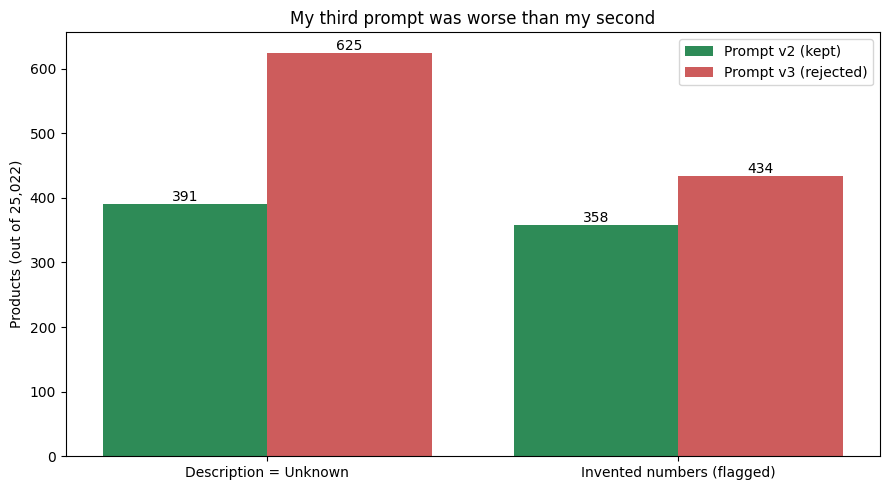

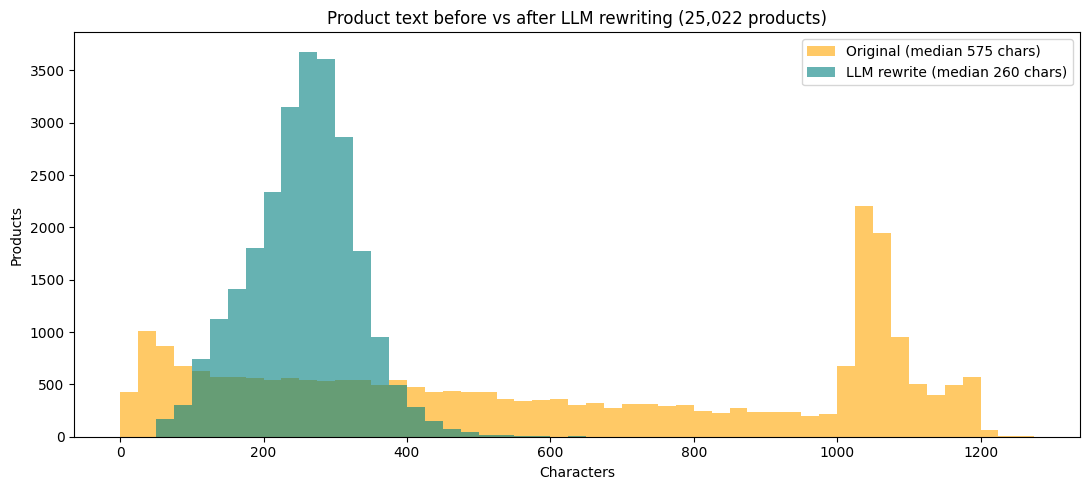

Saved assets/prompt_v2_vs_v3.png and assets/rewrite_length.png


In [25]:
# Cell 21: save two story charts to assets/
Path("assets").mkdir(exist_ok=True)

# 1) Prompt v2 vs v3 on all products: the "third prompt was worse" chart
v2_unknown_n = int(df["summary_v2"].apply(lambda s: field(s, "Description").lower() == "unknown").sum())
v3_unknown_n = int(df["summary_v3"].apply(lambda s: field(s, "Description").lower() == "unknown").sum())
v2_inv_n = final_rates["Invented numbers (flagged)"]
v3_inv_n = int(sum(bool(invented_numbers(t, s)) for t, s in zip(df["text"], df["summary_v3"])))
metrics_ = ["Description = Unknown", "Invented numbers (flagged)"]
v2_vals, v3_vals = [v2_unknown_n, v2_inv_n], [v3_unknown_n, v3_inv_n]
x = np.arange(len(metrics_))
plt.figure(figsize=(9, 5))
b1 = plt.bar(x - 0.2, v2_vals, width=0.4, color="seagreen", label="Prompt v2 (kept)")
b2 = plt.bar(x + 0.2, v3_vals, width=0.4, color="indianred", label="Prompt v3 (rejected)")
for bars in (b1, b2):
    for b in bars:
        plt.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom")
plt.xticks(x, metrics_)
plt.ylabel(f"Products (out of {N:,})")
plt.title("My third prompt was worse than my second")
plt.legend()
plt.tight_layout()
plt.savefig("assets/prompt_v2_vs_v3.png", dpi=150)
plt.show()

# 2) Text length before vs after rewriting (final v2 summaries)
plt.figure(figsize=(11, 5))
plt.hist(final_chk["orig_chars"], bins=range(0, 1300, 25), alpha=0.6, color="orange", label=f"Original (median {median_before:.0f} chars)")
plt.hist(final_chk["new_chars"], bins=range(0, 1300, 25), alpha=0.6, color="teal", label=f"LLM rewrite (median {median_after:.0f} chars)")
plt.xlabel("Characters"); plt.ylabel("Products")
plt.title(f"Product text before vs after LLM rewriting ({N:,} products)")
plt.legend()
plt.tight_layout()
plt.savefig("assets/rewrite_length.png", dpi=150)
plt.show()
print("Saved assets/prompt_v2_vs_v3.png and assets/rewrite_length.png")


## Step 17: Publish the `summary` column to Hugging Face

Adds `summary` next to `text` in the **same splits, same row order** as the published dataset (checked by assert), and updates the dataset card:
the rewrite method, prompt rules, quality numbers, prompt history, the train/serve note, and corrected language list.
The prompts are also saved to `prompts/` for reproducibility.

In [26]:
# Cell 22: publish to Hugging Face + update the dataset card + save the prompts
from huggingface_hub import HfApi

api = HfApi()
REPO_ID = "raghu619/shopify_category_lite"

# 1) Same splits, same order as the published data (verified), plus the summary column
out_dir = Path("data_hf")
out_dir.mkdir(exist_ok=True)
for s in tqdm(["train", "validation", "test"], desc="Writing splits", unit="split"):
    part = df[df["split"] == s][["text", "summary", "label", "full_category"]].reset_index(drop=True)
    assert len(part) == len(parts[s]) and (part["text"].values == parts[s]["text"].values).all(), f"{s}: order changed"
    part.to_parquet(out_dir / f"{s}.parquet", index=False)

# 2) Save the prompts (reproducibility)
Path("prompts").mkdir(exist_ok=True)
Path("prompts/rewrite_v2.txt").write_text(SYSTEM_PROMPT_V2)
Path("prompts/rewrite_v3_rejected.txt").write_text(SYSTEM_PROMPT_V3)

# 3) Update the dataset card
card = Path("dataset_card.md").read_text()
replacements = [
    ("- fr\nsize_categories", "- fr\n- de\n- it\n- pt\n- ja\nsize_categories"),
    ("| `text` | Model input: product title + description (description truncated to 1000 chars) |",
     "| `text` | Model input: product title + description (description truncated to 1000 chars) |\n"
     "| `summary` | The same product rewritten by an LLM into a standard 4-line English format (see below) |"),
    ("- **Languages kept as-is:** mostly English, roughly 9% Spanish, some French.",
     "- **Languages kept as-is:** mostly English, with Spanish, French, German, Italian, Portuguese and Japanese. "
     "(A Day 1 word heuristic estimated ~9% Spanish; it could not see other languages.)"),
]
for old, new in replacements:
    if old in card:
        card = card.replace(old, new)
    else:
        print("Card text not found (left unchanged):", old[:60])

rewrite_section = f"""## LLM rewrite (`summary` column)

Every product's `text` was rewritten by **gpt-4.1-nano** (OpenAI Batch API, temperature 0) into:

```
Title: ...
Brand: ... (or Unknown)
Description: one sentence (or Unknown)
Details: one sentence on key features (or Unknown)
```

Prompt rules ([prompt v2](https://github.com/raghu619/catalog-curation/blob/main/prompts/rewrite_v2.txt)): **no category line** (the category is the label),
never invent facts, write Unknown when information is missing, copy numbers exactly (decimal commas like `12,5 cm`),
remove IDs, URLs and contact details, translate to English. The 4-line structure is then **enforced in code** (`clean_summary`):
first block only, missing Title taken from the listing's first line.

**Quality, all {N:,} products:**

| Check | Result |
|---|---|
| Bad format | {final_rates['Bad format']} |
| Invented numbers flagged | {final_rates['Invented numbers (flagged)']:,} ({final_rates['Invented numbers (flagged)'] / N:.2%}); in 20 hand-labelled cases ~25% were real (rest were unit/year conversions), so roughly 0.35% |
| Description = Unknown | {final_rates['Description = Unknown']:,} ({final_rates['Description = Unknown'] / N:.2%}); 73 of these had real descriptions (mostly books and plants), a known limitation |
| Median length | {median_before:.0f} -> {median_after:.0f} characters |
| Cost | $0.77 for the full run |

**Prompt history:** v1 invented facts (a `12,5 cm` measurement became "12 sheets") and missed obvious brands.
v2 fixed both. v3 was tested on all products and **rejected**: Description = Unknown rose from 1.56% to 2.50% and flagged invented numbers from 1.43% to 1.73%.

**Train/serve note:** if you train on `summary`, rewrite new products with the same prompt and `clean_summary` before predicting.

"""
if "## LLM rewrite" not in card:
    card = card.replace("## Known limitations", rewrite_section + "## Known limitations")
Path("dataset_card.md").write_text(card)

# 4) Upload
api.upload_folder(folder_path=str(out_dir), path_in_repo="data", repo_id=REPO_ID, repo_type="dataset",
                  commit_message="Add LLM-rewritten summary column (prompt v2 + clean_summary)")
api.upload_file(path_or_fileobj="dataset_card.md", path_in_repo="README.md", repo_id=REPO_ID, repo_type="dataset",
                commit_message="Document the LLM rewrite step")
print(f"Published: https://huggingface.co/datasets/{REPO_ID}")


Writing splits:   0%|          | 0/3 [00:00<?, ?split/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Published: https://huggingface.co/datasets/raghu619/shopify_category_lite
